# Generate a 2D spectral target profile

This notebook builds the component-resolved profile `F_ljk = d_j G_jk(omega_l) d_k` used by `make_fiber_config(..., correction=True)`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
resol = 160

cwd = Path().resolve()
setup_root = next(
    (
        path
        for path in (cwd, *cwd.parents)
        if (path / "database_fiber").exists() and (path / "src").exists()
    ),
    Path("2d_setup").resolve(),
)
sys.path.insert(0, str(setup_root))

from src.generate_fiber_geom import load_geometry_by_id, plot_geometry
from src.bare_param import (
    generate_target_profile,
    make_frequency_grid,
    save_target_profile_csv,
    target_profile_path,
)


Choose the geometry used to compute the spectral target profile.

In [2]:
geometry_id = 5
geometry = load_geometry_by_id(geometry_id)

L1, L2 = geometry["lengths"]
N_A = geometry["N_A"]
atom_positions = geometry["atom_positions"]

print(f"Loaded geometry: {geometry['path'].name}")
print(f"lengths={geometry['lengths']}, N_A={N_A}, N_layer={geometry['N_layer']}, kind={geometry['kind']}")

Loaded geometry: geometry_id5.csv
lengths=[5. 5.], N_A=10, N_layer=1, kind=slab


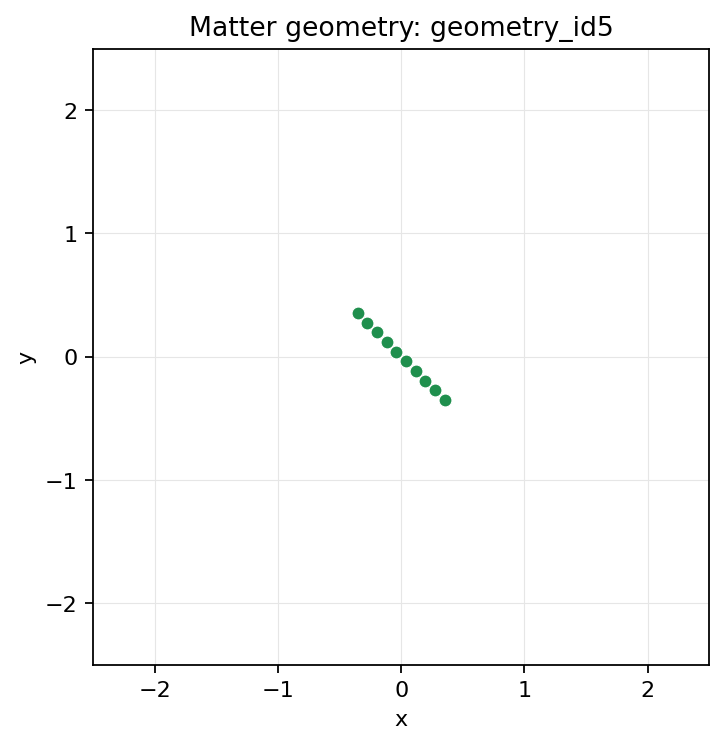

In [3]:
fig, ax = plt.subplots(figsize=(5, 5), dpi=resol)
ax.scatter(
    atom_positions[:, 0],
    atom_positions[:, 1],
    s=34,
    color="#1f8f4d",
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)
ax.set_xlim(-L1 / 2, L1 / 2)
ax.set_ylim(-L2 / 2, L2 / 2)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(color="0.9", linewidth=0.5)
ax.set_title(f"Matter geometry: {geometry['label']}")
plt.show()


Set the target atom parameters and the reference frequency data. `Omega_A` and `d_A` are arrays with one entry per atom.

In [4]:
Omega_A = 10 * np.pi * np.ones(geometry["N_A"])
d_A = np.ones(geometry["N_A"], dtype=float)

reference_cutoffs = {
    "ir_cutoff": 0 * np.pi,
    "uv_cutoff": 20 * np.pi,
}

nb_omega_values = 200
omega_values = np.linspace(0.1 * np.pi, 19.9 * np.pi, nb_omega_values)
frequency_set = make_frequency_grid(omega_values)

radius_cache_decimals = 4 if geometry["kind"] == "slab" else 12
print(f"N_omega = {len(frequency_set)}")
print(f"N_spectral_entries = {len(frequency_set) * geometry['N_A'] ** 2}")
print(f"radius_cache_decimals = {radius_cache_decimals}")


N_omega = 200
N_spectral_entries = 20000
radius_cache_decimals = 4


In [5]:
target_profile = generate_target_profile(
    frequency_set,
    atom_positions=atom_positions,
    Omega_j=Omega_A,
    d_j=d_A,
    reference_cutoffs=reference_cutoffs,
    id_geom=geometry_id,
    epsabs=1e-7,
    epsrel=1e-7,
    cache_decimals=radius_cache_decimals,
    progress=True,
)

target_profile.head()


  0%|          | 0/200 [00:00<?, ?it/s]

,omega,j,k,W,F_real,F_imag
0,0.314159,0,0,0.00005,-0.048536,-0.000656
1,0.314159,0,1,0.00005,-0.003957,-0.000700
2,0.314159,0,2,0.00005,-0.002763,-0.000726
3,0.314159,0,3,0.00005,-0.002169,-0.000741
4,0.314159,0,4,0.00005,-0.001755,-0.000748


In [6]:
output_path = target_profile_path()
save_target_profile_csv(target_profile, output_path)

print(f"Saved target profile to: {output_path}")
print("make_fiber_config(correction=True) will find bare params generated from this profile.")


Saved target profile to: /Users/romainpiron/Documents/NII_local/waveguide-qed-simulator/2d_setup/database_fiber/target_profiles/target_profile_id1.csv
make_fiber_config(correction=True) will find bare params generated from this profile.
